In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv(
    "../dataset/APL_Logistics.csv",
    encoding="latin1"
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df_original = df.copy()

df_clean = df.copy()

print("Original dataset preserved!")
print("Working dataset created!")

Original dataset preserved!
Working dataset created!


In [4]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Name,Product Price,Shipping Mode
0,DEBIT,6,4,159.69,472.45,Late delivery,1,9,Cardio Equipment,Brownsville,...,5,499.95,472.45,159.69,South Asia,Maharashtra,COMPLETE,Nike Men's Free 5.0+ Running Shoe,99.99,Standard Class
1,DEBIT,4,4,48.71,167.96,Shipping on time,0,29,Shop By Sport,Littleton,...,5,199.95,167.96,48.71,Central America,Cortés,ON_HOLD,Under Armour Girls' Toddler Spine Surge Runni,39.99,Standard Class
2,DEBIT,4,4,87.36,181.99,Shipping on time,0,48,Water Sports,Littleton,...,1,199.99,181.99,87.36,Central America,Cortés,ON_HOLD,Pelican Sunstream 100 Kayak,199.99,Standard Class
3,DEBIT,6,4,-41.89,175.99,Late delivery,1,48,Water Sports,Littleton,...,1,199.99,175.99,-41.89,East of USA,Nueva York,COMPLETE,Pelican Sunstream 100 Kayak,199.99,Standard Class
4,DEBIT,6,4,10.00,40.00,Late delivery,1,24,Women's Apparel,Littleton,...,1,50.00,40.00,10.00,East of USA,Nueva York,COMPLETE,Nike Men's Dri-FIT Victory Golf Polo,50.00,Standard Class


In [5]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 180519
Number of Columns: 40


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 40 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Fname                 180519 non-null  str    
 12  Customer Id                    180519 non

In [7]:
df.describe()

,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Customer Id,Customer Zipcode,Department Id,Latitude,...,Order Customer Id,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Product Price
count,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180516.000000,180519.000000,180519.000000,...,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000
mean,3.497654,2.931847,21.974989,183.107607,0.548291,31.851451,6691.379495,35921.126914,5.443460,29.719955,...,6691.379495,20.664741,0.101668,141.232547,0.120647,2.127638,203.772092,183.107607,21.974989,141.232547
std,1.623722,1.374449,104.433526,120.043668,0.497664,15.640064,4162.918106,37542.461122,1.629246,9.813646,...,4162.918106,21.800901,0.070415,139.732489,0.466796,1.453451,132.273075,120.043668,104.433526,139.732489
min,0.000000,0.000000,-4274.980000,7.490000,0.000000,2.000000,1.000000,603.000000,2.000000,-33.937553,...,1.000000,0.000000,0.000000,9.990000,-2.750000,1.000000,9.990000,7.490000,-4274.980000,9.990000
25%,2.000000,2.000000,7.000000,104.380000,0.000000,18.000000,3258.500000,725.000000,4.000000,18.265432,...,3258.500000,5.400000,0.040000,50.000000,0.080000,1.000000,119.980000,104.380000,7.000000,50.000000
50%,3.000000,4.000000,31.520000,163.990000,1.000000,29.000000,6457.000000,19380.000000,5.000000,33.144863,...,6457.000000,14.000000,0.100000,59.990000,0.270000,1.000000,199.920000,163.990000,31.520000,59.990000
75%,5.000000,4.000000,64.800000,247.400000,1.000000,45.000000,9779.000000,78207.000000,7.000000,39.279617,...,9779.000000,29.990000,0.160000,199.990000,0.360000,3.000000,299.950000,247.400000,64.800000,199.990000
max,6.000000,4.000000,911.800000,1939.990000,1.000000,76.000000,20757.000000,99205.000000,12.000000,48.781933,...,20757.000000,500.000000,0.250000,1999.990000,0.500000,5.000000,1999.990000,1939.990000,911.800000,1999.990000


In [8]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

Customer Lname      8
Customer Zipcode    3
dtype: int64


In [9]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [10]:
print(df['Late_delivery_risk'].value_counts())

Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64


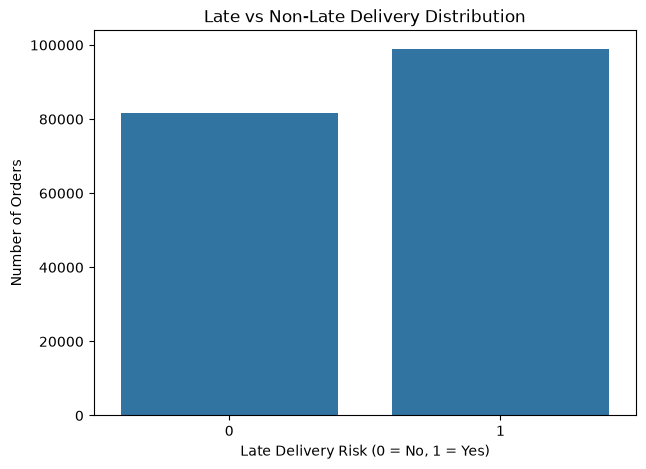

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Late_delivery_risk'
)

plt.title('Late vs Non-Late Delivery Distribution')
plt.xlabel('Late Delivery Risk (0 = No, 1 = Yes)')
plt.ylabel('Number of Orders')

plt.show()

In [12]:
print(
    df['Late_delivery_risk']
    .value_counts(normalize=True) * 100
)

Late_delivery_risk
1    54.829132
0    45.170868
Name: proportion, dtype: float64


In [13]:
columns_to_drop = [
    'Days for shipping (real)',
    'Delivery Status',
    'Order Status',

    'Customer Fname',
    'Customer Lname',
    'Customer Street',
    'Customer Zipcode',
    'Customer Id',
    'Order Customer Id',

    'Category Id',
    'Department Id',

    'Benefit per order',
    'Order Profit Per Order',
    'Order Item Profit Ratio',
    'Sales per customer',

    'Customer City',
    'Customer Country',
    'Customer State',

    'Product Name',

    'Sales',
    'Order Item Total'
]

df_clean = df_clean.drop(
    columns=columns_to_drop
)

print("Unnecessary columns removed!")
print("Remaining shape:", df_clean.shape)

Unnecessary columns removed!
Remaining shape: (180519, 19)


In [14]:
print(df_clean['Late_delivery_risk'].value_counts())

print("\nUnique target values:")
print(df_clean['Late_delivery_risk'].unique())

Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

Unique target values:
[1 0]


In [15]:
print(
    "Missing target values:",
    df_clean['Late_delivery_risk'].isnull().sum()
)

Missing target values: 0


In [16]:
categorical_columns = df_clean.select_dtypes(
    include='object'
).columns

for col in categorical_columns:
    df_clean[col] = df_clean[col].str.strip()

print("Categorical values standardized!")

Categorical values standardized!


In [17]:
print("Final Dataset Shape:", df_clean.shape)

print("\nDataset Information:")
df_clean.info()

print("\nStatistical Summary:")
display(df_clean.describe())

print("\nMissing Values:")
print(df_clean.isnull().sum())

Final Dataset Shape: (180519, 19)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 19 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipment (scheduled)  180519 non-null  int64  
 2   Late_delivery_risk             180519 non-null  int64  
 3   Category Name                  180519 non-null  str    
 4   Customer Segment               180519 non-null  str    
 5   Department Name                180519 non-null  str    
 6   Latitude                       180519 non-null  float64
 7   Longitude                      180519 non-null  float64
 8   Market                         180519 non-null  str    
 9   Order City                     180519 non-null  str    
 10  Order Country                  180519 non-null  str    
 11  Order Item Discount            180519 non-null

,Days for shipment (scheduled),Late_delivery_risk,Latitude,Longitude,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Quantity,Product Price
count,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000
mean,2.931847,0.548291,29.719955,-84.915675,20.664741,0.101668,141.232547,2.127638,141.232547
std,1.374449,0.497664,9.813646,21.433241,21.800901,0.070415,139.732489,1.453451,139.732489
min,0.000000,0.000000,-33.937553,-158.025986,0.000000,0.000000,9.990000,1.000000,9.990000
25%,2.000000,0.000000,18.265432,-98.446312,5.400000,0.040000,50.000000,1.000000,50.000000
50%,4.000000,1.000000,33.144863,-76.847908,14.000000,0.100000,59.990000,1.000000,59.990000
75%,4.000000,1.000000,39.279617,-66.370583,29.990000,0.160000,199.990000,3.000000,199.990000
max,4.000000,1.000000,48.781933,115.263077,500.000000,0.250000,1999.990000,5.000000,1999.990000



Missing Values:
Type                             0
Days for shipment (scheduled)    0
Late_delivery_risk               0
Category Name                    0
Customer Segment                 0
Department Name                  0
Latitude                         0
Longitude                        0
Market                           0
Order City                       0
Order Country                    0
Order Item Discount              0
Order Item Discount Rate         0
Order Item Product Price         0
Order Item Quantity              0
Order Region                     0
Order State                      0
Product Price                    0
Shipping Mode                    0
dtype: int64


In [18]:
for col in categorical_columns:
    print("\n", col)
    print(df_clean[col].value_counts().head(10))


 Type
Type
DEBIT       69295
TRANSFER    49883
PAYMENT     41725
CASH        19616
Name: count, dtype: int64

 Category Name
Category Name
Cleats                  24551
Men's Footwear          22246
Women's Apparel         21035
Indoor/Outdoor Games    19298
Fishing                 17325
Water Sports            15540
Camping & Hiking        13729
Cardio Equipment        12487
Shop By Sport           10984
Electronics              3156
Name: count, dtype: int64

 Customer Segment
Customer Segment
Consumer       93504
Corporate      54789
Home Office    32226
Name: count, dtype: int64

 Department Name
Department Name
Fan Shop      66861
Apparel       48998
Golf          33220
Footwear      14525
Outdoors       9686
Fitness        2479
Discs Shop     2026
Technology     1465
Pet Shop        492
Book Shop       405
Name: count, dtype: int64

 Market


Market
LATAM           51594
Europe          50252
Pacific Asia    41260
USCA            25799
Africa          11614
Name: count, dtype: int64

 Order City
Order City
Santo Domingo    2211
New York City    2202
Los Angeles      1845
Tegucigalpa      1783
Managua          1682
Mexico City      1484
Manila           1381
Philadelphia     1302
San Francisco    1297
London           1187
Name: count, dtype: int64

 Order Country
Order Country
Estados Unidos    24840
Francia           13222
México            13172
Alemania           9564
Australia          8497
Brasil             7987
Reino Unido        7302
China              5758
Italia             4989
India              4783
Name: count, dtype: int64

 Order Region
Order Region
Central America    28341
Western Europe     27109
South America      14935
Oceania            10148
Northern Europe     9792
Southeast Asia      9539
Southern Europe     9431
Caribbean           8318
West of USA         7993
South Asia          7731
Name: count, 

In [19]:
df_clean.to_csv(
    "../dataset/APL_Logistics_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
